# Single-model pipeline — stage-by-stage experiments

Phase 2 runs **one** background model whose foreground mask feeds the structural
filter and the dwell-time FSM (see `readme.md`). This notebook:

1. exposes every tunable **parameter** of the pipeline with a short description,
2. runs the pipeline over both study cases (**busStation**, **canoe**) and shows
   a per-case **grid** of the four pipeline stages —
   *input → HSV shadow filter → foreground (bg-model output) → after morphology*,
3. **evaluates** the result against the CDNET groundtruth for both cases.

The parameters cell is the single place to change the experiment; every later
cell reads from it, so edit-and-rerun sweeps only the values you care about.

In [8]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scr import PipelineConfig, SignOfLifePipeline
from scr.config import (
    BGSConfig,
    BlobConfig,
    DenoiseMethod,
    FeatureConfig,
    FeatureKind,
    Implementation,
    PreprocessConfig,
    ShadowConfig,
)
from scr.features import ShadowSuppressor
from scr.native_ops import bgr_to_hsv, hsv_to_bgr
from evaluate import EvaluationResult, accumulate_counts, frame_number, index_masks

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}

## 1. Parameters

Everything below is an experiment knob. Grouped by pipeline layer; the defaults
reproduce the Phase-2 recommendation (native `running_gaussian`, α = 0.1, QVGA).

In [9]:
# ---- Dataset -------------------------------------------------------------
# 'data_0_1fps' is the decimated 0.1-fps set used in Phase 1 (few frames, quick,
# reproduces the committed F-scores). Switch to Path('data') for the full
# native-fps sequences (hundreds of frames -> richer grid and evaluation).
DATASET_ROOT = Path("data_0_1fps")
CASES = ["busStation", "canoe"]

# ---- Layer 0: preprocessing ----------------------------------------------
RESIZE = (320, 240)               # QVGA (width, height); None keeps native size
DENOISE = DenoiseMethod.GAUSSIAN  # sensor-noise filter before modelling

# ---- Implementation ------------------------------------------------------
# NATIVE = pure-NumPy path with no OpenCV dependency for the model (scr/models),
# the HSV shadow veto and the morphology (scr/native_ops); LIB = OpenCV/pybgs.
# The native ops are bit-exact with OpenCV, so switching this does not change
# the masks or scores -- only the dependency (the C / Alif port targets NATIVE).
IMPLEMENTATION = Implementation.NATIVE

# ---- Layer 2: feature transform + HSV shadow veto ------------------------
FEATURE = FeatureKind.GRAY        # differencing metric: gray / lbp / chromaticity
SHADOW = ShadowConfig(
    enabled=True,
    value_ratio_min=0.40,         # a cast shadow keeps 40-95% of the background
    value_ratio_max=0.95,         #   brightness (V_frame / V_background) ...
    saturation_delta_max=40.0,    #   ... with roughly unchanged saturation ...
    hue_delta_max=12.0,           #   ... and hue (OpenCV 0-179 scale)
    implementation=IMPLEMENTATION,  # native = scr.native_ops.bgr_to_hsv
)

# ---- Layer 1: background model -------------------------------------------
BACKEND = "running_gaussian"            # Phase-2 pick: best F1-per-resource
ALPHA = 0.10                            # learning rate; ~1/ALPHA frames to absorb
THRESHOLD = 25.0                        # native-backend foreground threshold

# ---- Layer 3: morphology + area gate -------------------------------------
BLOB = BlobConfig(
    min_area=150,                 # drop blobs smaller than this many pixels
    open_kernel=3,                # opening removes speckle ...
    close_kernel=7,               # ... closing bridges small gaps
    implementation=IMPLEMENTATION,  # native = scr.native_ops morphology
)

# ---- Visualisation / scoring ---------------------------------------------
GRID_MAX_FRAMES = 6               # rows per case grid (evenly sampled)
FG_THRESHOLD = 127                # prediction > this counts as foreground


def build_config() -> PipelineConfig:
    """Assemble a PipelineConfig from the parameters above."""
    return PipelineConfig(
        preprocess=PreprocessConfig(resize=RESIZE, denoise=DENOISE),
        feature=FeatureConfig(kind=FEATURE),
        shadow=SHADOW,
        bgs=BGSConfig(
            backend=BACKEND,
            learning_rate=ALPHA,
            threshold=THRESHOLD,
            implementation=IMPLEMENTATION,
        ),
        blob=BLOB,
    )


print("Model :", IMPLEMENTATION.value, BACKEND, f"(alpha={ALPHA})")
print("Input :", DATASET_ROOT, "->", CASES, f"resized to {RESIZE}")

Model : native running_gaussian (alpha=0.1)
Input : data_0_1fps -> ['busStation', 'canoe'] resized to (320, 240)


## 2. Run the pipeline

`run_case` feeds a whole sequence through a fresh `SignOfLifePipeline` and keeps,
per frame, the four stage images plus the frame number for scoring.

The **HSV shadow filter** panel is reconstructed exactly: the veto uses the
background estimate as of the *previous* frame, so we snapshot
`pipeline.model.background_bgr` **before** each `process()` call and feed it to a
`ShadowSuppressor` built from the same `SHADOW` config. With `IMPLEMENTATION =
NATIVE`, that veto (and the panel's red tint below) runs the pure-NumPy
`bgr_to_hsv` / `hsv_to_bgr` from `scr.native_ops`, and the morphology runs the
native `morphology_ex` -- no OpenCV in the HSV or morphology stages.

In [10]:
def discover_frames(case: str) -> list[Path]:
    directory = DATASET_ROOT / case / "input"
    return sorted(
        p for p in directory.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES
    )


def run_case(case: str) -> list[dict]:
    """Run the pipeline over one case, returning per-frame stage images."""
    pipeline = SignOfLifePipeline.from_config(build_config())
    suppressor = ShadowSuppressor(SHADOW)  # same config -> reproduces the veto
    records: list[dict] = []
    for path in discover_frames(case):
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is None:
            continue
        background = pipeline.model.background_bgr  # state after previous frame
        result = pipeline.process(image)
        records.append(
            {
                "number": frame_number(path),
                "input": result.frame.bgr,
                "shadow": suppressor.shadow_mask(result.frame, background),
                "foreground": result.foreground,
                "filtered": result.filtered_mask,
            }
        )
    return records


results = {case: run_case(case) for case in CASES}
for case in CASES:
    print(f"{case}: {len(results[case])} frames processed")

busStation: 6 frames processed
canoe: 5 frames processed


## 3. Stage grid per case

Each row is one frame; the columns follow the pipeline left to right:

| Column | Content |
| --- | --- |
| **Input** | Preprocessed (denoised, QVGA) frame |
| **HSV shadow filter** | Detected cast-shadow pixels tinted red, via the native BGR→HSV→BGR round-trip |
| **Foreground (bg model)** | The model's foreground mask — the veto has already removed the red pixels |
| **After morphology** | Foreground after opening/closing and the area gate — the pipeline's final mask |

In [11]:
COLUMN_TITLES = ["Input", "HSV shadow filter", "Foreground (bg model)", "After morphology"]


def shadow_overlay(bgr: np.ndarray, shadow: np.ndarray) -> np.ndarray:
    """Tint shadow pixels red *in HSV space* and convert back.

    This exercises the native round-trip end to end: BGR -> HSV with
    ``bgr_to_hsv``, recolour the detected-shadow pixels (hue = red, full
    saturation, value kept so the shadow's own shading stays visible), then
    HSV -> BGR with ``hsv_to_bgr``. The final BGR -> RGB flip for matplotlib is
    a plain NumPy channel reversal, so the whole panel is OpenCV-free.
    """
    hsv = bgr_to_hsv(bgr).copy()          # native BGR -> HSV
    mask = shadow > 0
    hsv[mask, 0] = 0                       # hue -> red
    hsv[mask, 1] = 255                     # full saturation
    tinted = hsv_to_bgr(hsv)              # native HSV -> BGR
    return tinted[:, :, ::-1]            # BGR -> RGB (NumPy)


def sample_rows(records: list[dict], k: int) -> list[dict]:
    """Evenly sample up to k frames across the sequence."""
    if len(records) <= k:
        return records
    idx = np.linspace(0, len(records) - 1, k).round().astype(int)
    return [records[i] for i in idx]


def show_grid(case: str, records: list[dict]) -> None:
    rows = sample_rows(records, GRID_MAX_FRAMES)
    fig, axes = plt.subplots(len(rows), 4, figsize=(13, 3.1 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, record in enumerate(rows):
        panels = [
            record["input"][:, :, ::-1],  # BGR -> RGB (NumPy)
            shadow_overlay(record["input"], record["shadow"]),
            record["foreground"],
            record["filtered"],
        ]
        for c, (ax, image) in enumerate(zip(axes[r], panels)):
            if image.ndim == 3:
                ax.imshow(image)
            else:
                ax.imshow(image, cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(COLUMN_TITLES[c], fontsize=11)
            if c == 0:
                ax.set_ylabel(f"frame #{record['number']}", fontsize=10)
    fig.suptitle(f"{case} — pipeline stages ({BACKEND}, alpha={ALPHA})", fontsize=13)
    fig.tight_layout()
    plt.show()

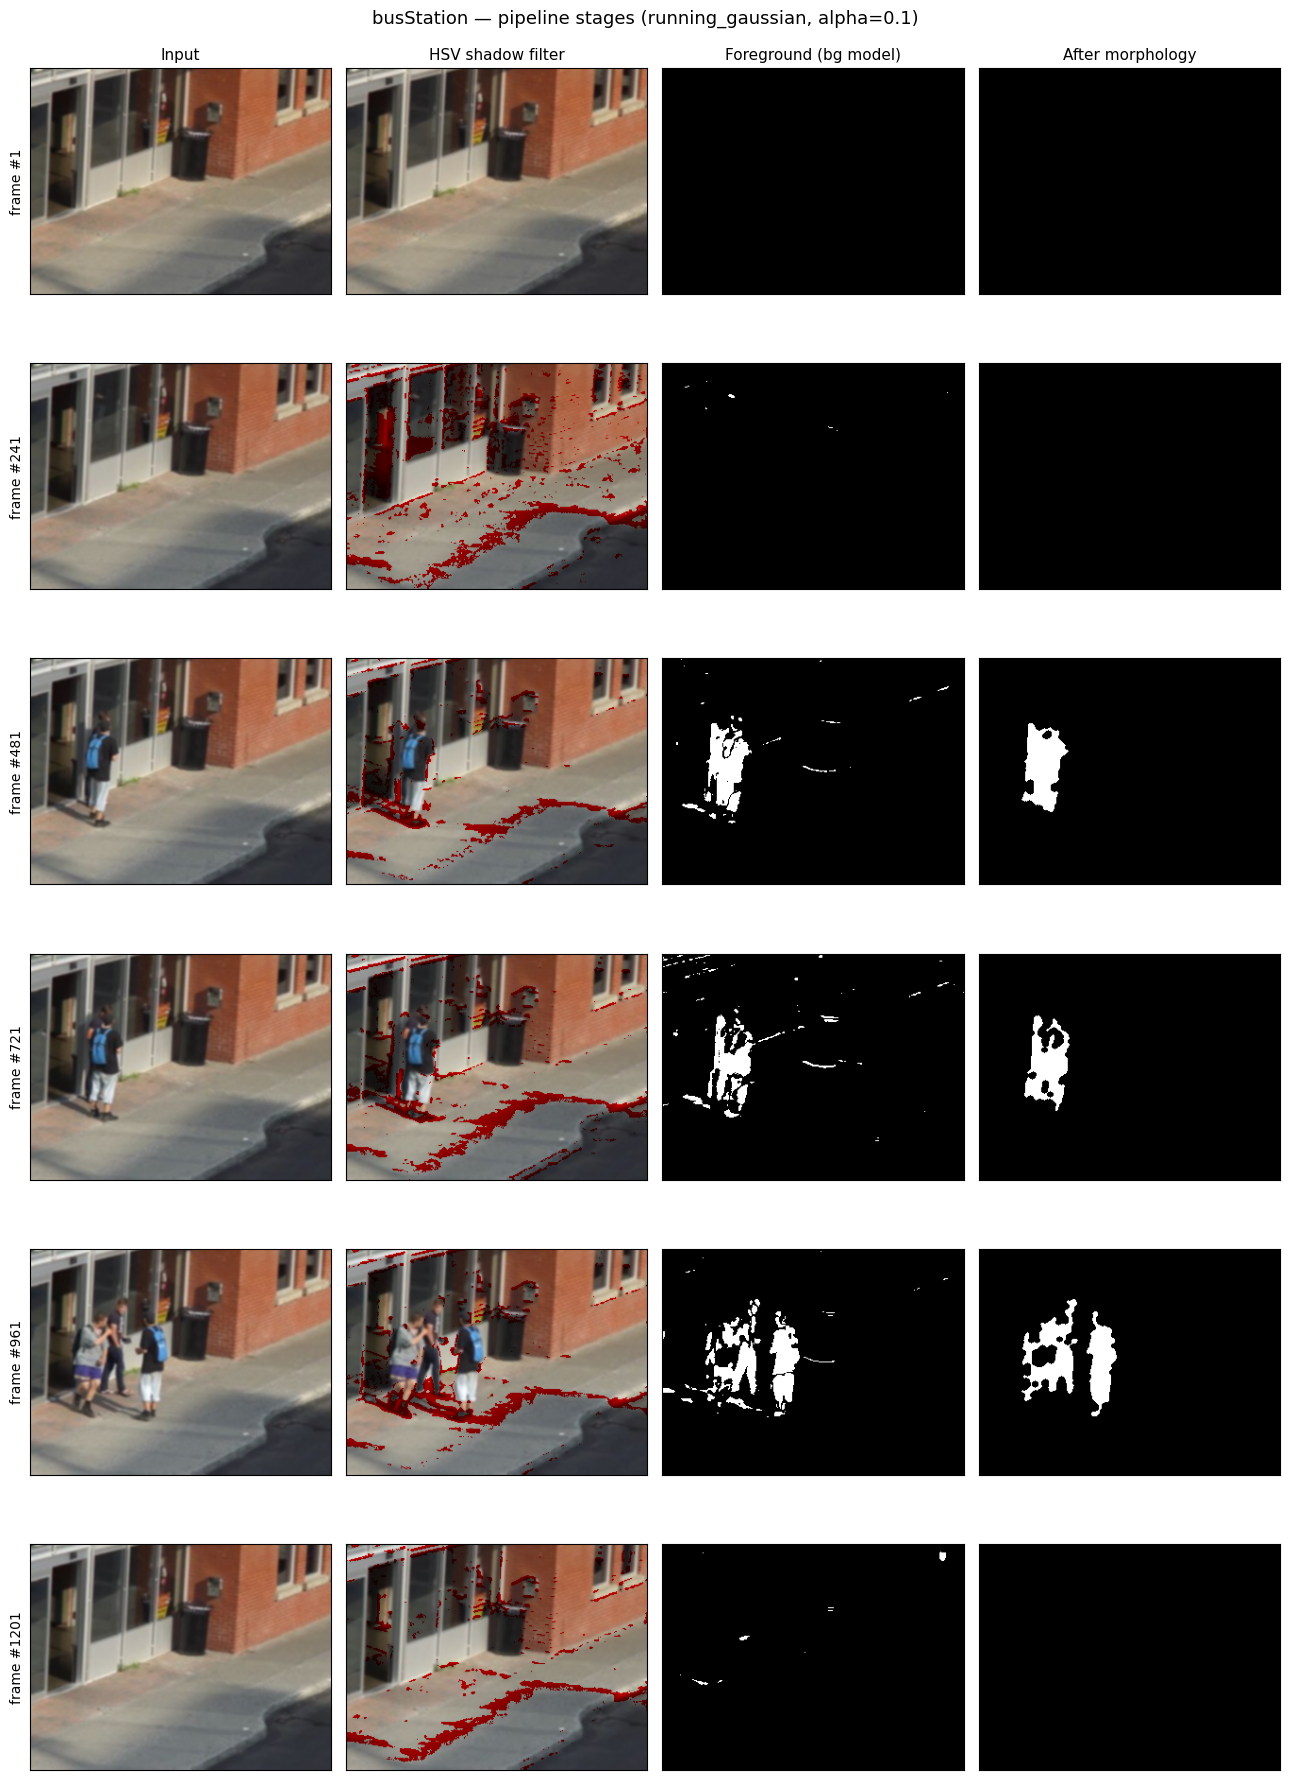

In [12]:
show_grid('busStation', results['busStation'])

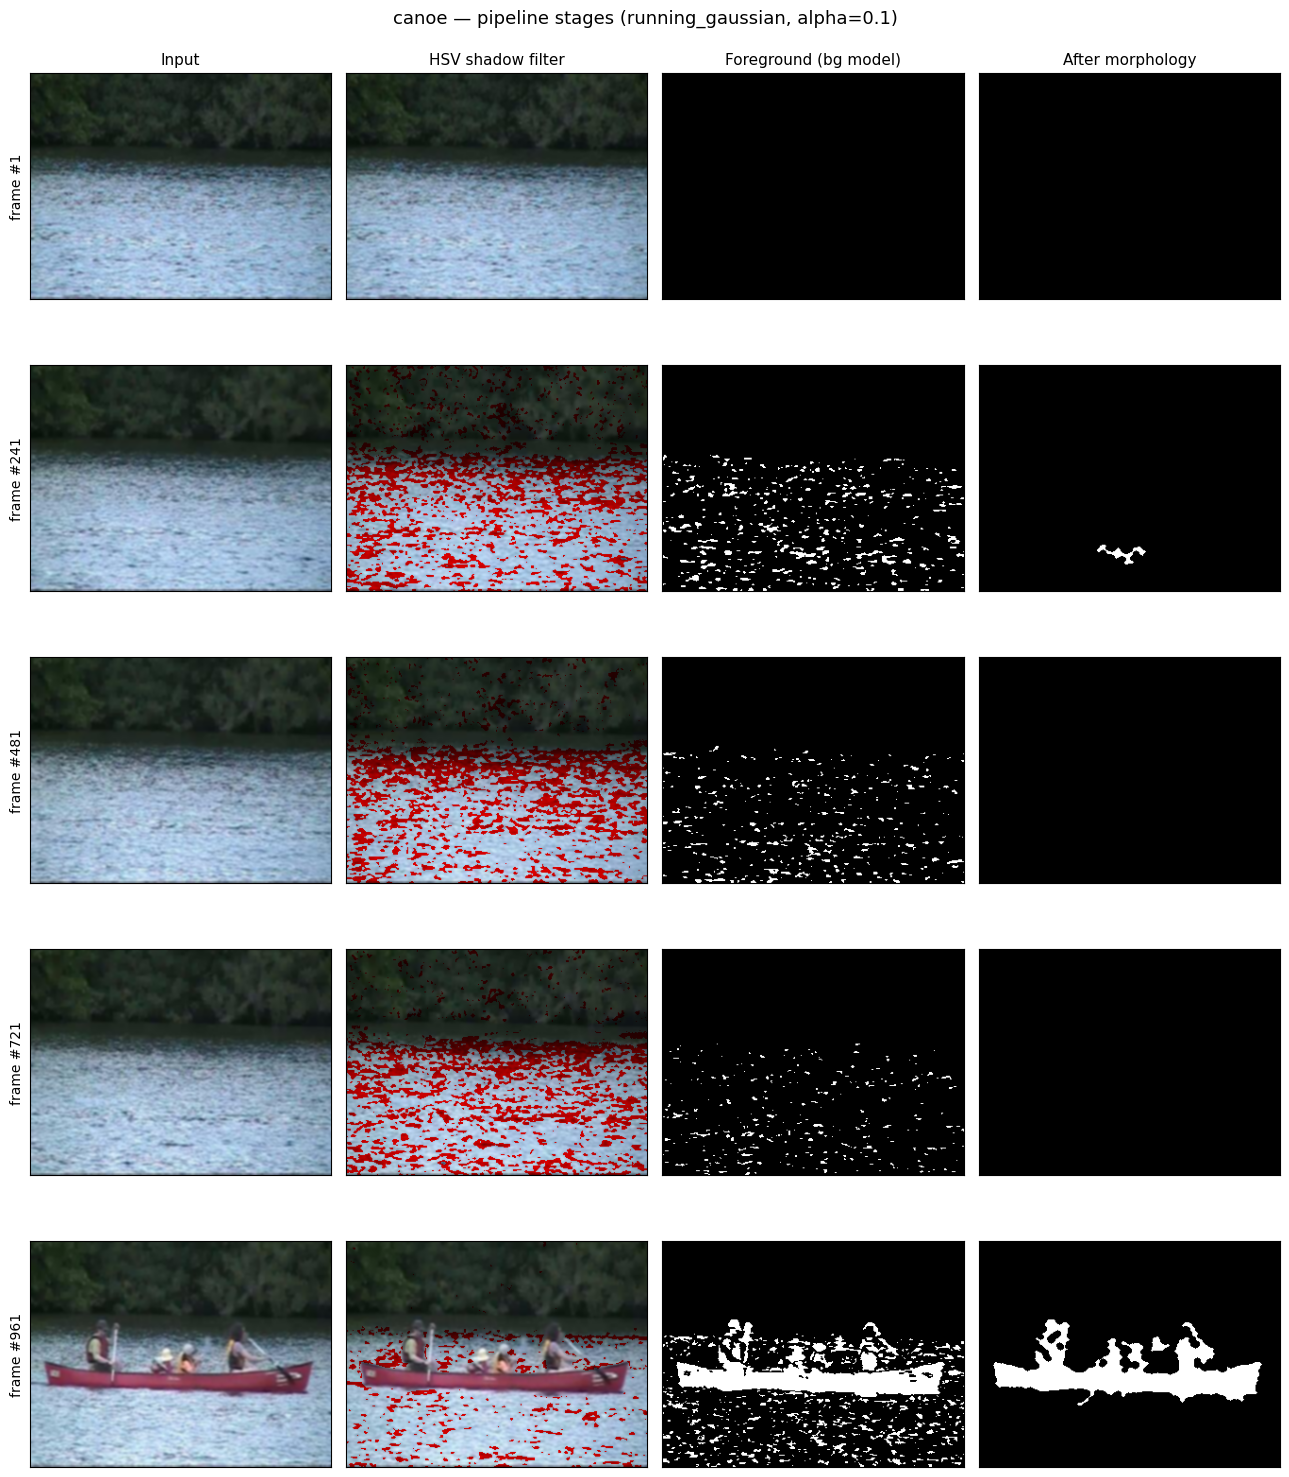

In [13]:
show_grid('canoe', results['canoe'])

## 4. Evaluation

Both masks are scored against the CDNET groundtruth: the raw **foreground**
(bg-model output, comparable to the Phase-1 model sweep) and the **filtered**
mask (the pipeline's final product, after morphology). Following the CDNET
protocol, only pixels whose groundtruth is exactly `0` or `255` are counted;
shadow (50), unknown (170) and outside-ROI (85) pixels are ignored, and frames
with no such pixels are skipped. Predictions are resized to the groundtruth
resolution inside `accumulate_counts`.

In [14]:
def evaluate_case(case: str, records: list[dict], mask_key: str) -> dict:
    groundtruth = index_masks(DATASET_ROOT / case / "groundtruth")
    tp = fp = fn = tn = frames = 0
    for record in records:
        number = record["number"]
        if number not in groundtruth:
            continue
        gt = cv2.imread(str(groundtruth[number]), cv2.IMREAD_GRAYSCALE)
        counts = accumulate_counts(gt, record[mask_key], FG_THRESHOLD)
        if sum(counts) == 0:  # groundtruth is all void for this frame
            continue
        tp += counts[0]
        fp += counts[1]
        fn += counts[2]
        tn += counts[3]
        frames += 1
    result = EvaluationResult.from_counts(tp, fp, fn, tn, frames)
    return {
        "case": case,
        "mask": mask_key,
        "eval frames": result.frames,
        "precision": result.precision,
        "recall": result.recall,
        "F-measure": result.f_measure,
        "IoU": result.iou,
    }


rows = [
    evaluate_case(case, results[case], mask_key)
    for case in CASES
    for mask_key in ("foreground", "filtered")
]
scores = pd.DataFrame(rows)
scores.style.format(
    {"precision": "{:.3f}", "recall": "{:.3f}", "F-measure": "{:.3f}", "IoU": "{:.3f}"}
).hide(axis="index").background_gradient(subset=["F-measure"], cmap="RdYlGn", vmin=0, vmax=1)

case,mask,eval frames,precision,recall,F-measure,IoU
busStation,foreground,4,0.873,0.622,0.726,0.570
busStation,filtered,4,0.988,0.682,0.807,0.676
canoe,foreground,1,0.607,0.859,0.711,0.552
canoe,filtered,1,0.917,0.935,0.926,0.862


### Notes

- **Thin groundtruth at 0.1 fps.** The decimated set exposes only a handful of
  labelled frames (busStation ≈ 3–4, canoe = 1), so the scores are indicative,
  not statistically tight. Point `DATASET_ROOT` at `data` for a full-sequence
  F-measure over the temporal ROI.
- **`foreground` vs `filtered`.** Morphology and the area gate trade recall for
  precision; on dynamic-background clips (canoe water) they legitimately remove
  most of the mask, which can drop the filtered F-measure toward zero.
- **One knob, one trade-off.** With a single model, `ALPHA` balances crisp
  segmentation (higher α) against retaining a deposited object for the dwell FSM
  (lower α). Sweep it here and watch the grid + scores move together.